# Support Ticket Triage: EDA, Baseline vs Neural Model, Evaluation
Predicts **Category** and **Urgency** from raw ticket text. Labels are read from the trained model, so the notebook works for the synthetic data or your own / Kaggle data (set `DATA_PATH` in the first code cell).

Flow: load -> clean -> EDA -> imbalance -> split -> baseline (TF-IDF + LR) -> BiLSTM (PyTorch) -> compare -> error analysis -> robustness.

> **Data note.** This notebook uses a *synthetic* dataset (`triage/data.py`) with deliberate noise: ambiguous severity,
> distractor sentences, typos, missing/misleading urgency cues and ~3% flipped category labels. Scores are therefore
> not 100%, but they are **not** a forecast of real-world performance. Run `python -m triage.train --data your.csv` to retrain on real tickets.

In [1]:
import sys, os, json, warnings; sys.path.insert(0, ".."); warnings.filterwarnings("ignore")
DATA_PATH = None            # None = built-in synthetic data. For Kaggle: "../customer_support_tickets.csv"
ARTIFACTS = "../artifacts"  # must match the folder you trained into (python -m triage.train --artifacts ...)
os.environ["TRIAGE_ARTIFACTS"] = ARTIFACTS
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from triage import config as C
from triage.data import load_or_create, clean_dataframe, split
from triage.preprocess import tokenize
from triage.inference import Predictor
sns.set_theme(style="whitegrid"); pd.set_option("display.max_colwidth", 110)
meta = json.load(open(f"{ARTIFACTS}/metadata.json"))          # labels come from the trained model, so any dataset works
CATS, URGS = meta["categories"], meta["urgencies"]

## 1. Load and inspect

In [2]:
raw = load_or_create(DATA_PATH)
print("shape:", raw.shape)
print("missing/empty text:", int(raw.text.isna().sum() + (raw.text.fillna('').str.strip() == '').sum() - raw.text.isna().sum()), "empty +", int(raw.text.isna().sum()), "null")
print("duplicate rows (text+labels):", int(raw.duplicated(["text", "category", "urgency"]).sum()))
raw.head(8)

shape: (6120, 4)
missing/empty text: 30 empty + 30 null
duplicate rows (text+labels): 130


,ticket_id,text,category,urgency
0,T102094,"Hi team, Just curious. Could you explain the tax on my latest statement. My order number is 81768. Thank you",Billing,Low
1,T101612,"Good morning, I would appreciate a quick reply. There is an unexpected fee on my subscription. I was remov...",Billing,Medium
2,T105858,"Hello, Notifications are delayed by several hours. Could you explain the tax on my latest sttement. I need...",Technical,Medium
3,T104294,"Hi, Whenever you get a chance. Can I merge two of my workspaces! Regards",Billing,Low
4,T102571,"Hello, Whenever you get a chance. The font in the mobile app looks small on my tablet. Thanks Elena",Technical,Low
5,T103781,"hi, could you explain the tax on my latest statement. my order number is 45394... regards",Billing,Low
6,T101005,"Hi, I need this sorted this week. Notifications are delayed by several hours. My oredr number is 88769! Ch...",Technical,Medium
7,T104701,Just curious. The dashboard loads very slowly since the last update... Cheers Ana,Technical,Medium


## 2. Cleaning
Normalise text (URLs/emails/numbers -> tokens, keep SHOUTING as a `<caps>` token), drop empty rows, de-duplicate.

In [3]:
df = clean_dataframe(raw)
print(f"{len(raw)} raw rows -> {len(df)} clean rows ({len(raw)-len(df)} removed)")
df[["text", "clean", "category", "urgency"]].sample(5, random_state=1)

6120 raw rows -> 5960 clean rows (160 removed)


,text,clean,category,urgency
4146,"Hell,o I need a formal quote for our company by Friday. I am locked out of my admin account and our deadli...","hell,o i need a formal quote for our company by friday. i am locked out of my admin account and our deadli...",General,Medium
4103,"Hi team, My profile shows the wrong subscription tier. When you have time! Thank you","hi team, my profile shows the wrong subscription tier. when you have time! thank you",Account,Low
5439,I have been waiting a week for a reply on my partnership request. My order number is 39588. I would apprec...,i have been waiting a week for a reply on my partnership request. my order number is <num> . i would appre...,General,Medium
997,"Good morning, I need this sorted this week. The app crashes whenever I open the reports page!","good morning, i need this sorted this week. the app crashes whenever i open the reports page!",Technical,Medium
5908,"Good morning, When you have time. Where can I find your documentation. My order number is 39730... Thank y...","good morning, when you have time. where can i find your documentation. my order number is <num> ... thank ...",General,Low


## 3. Exploratory data analysis

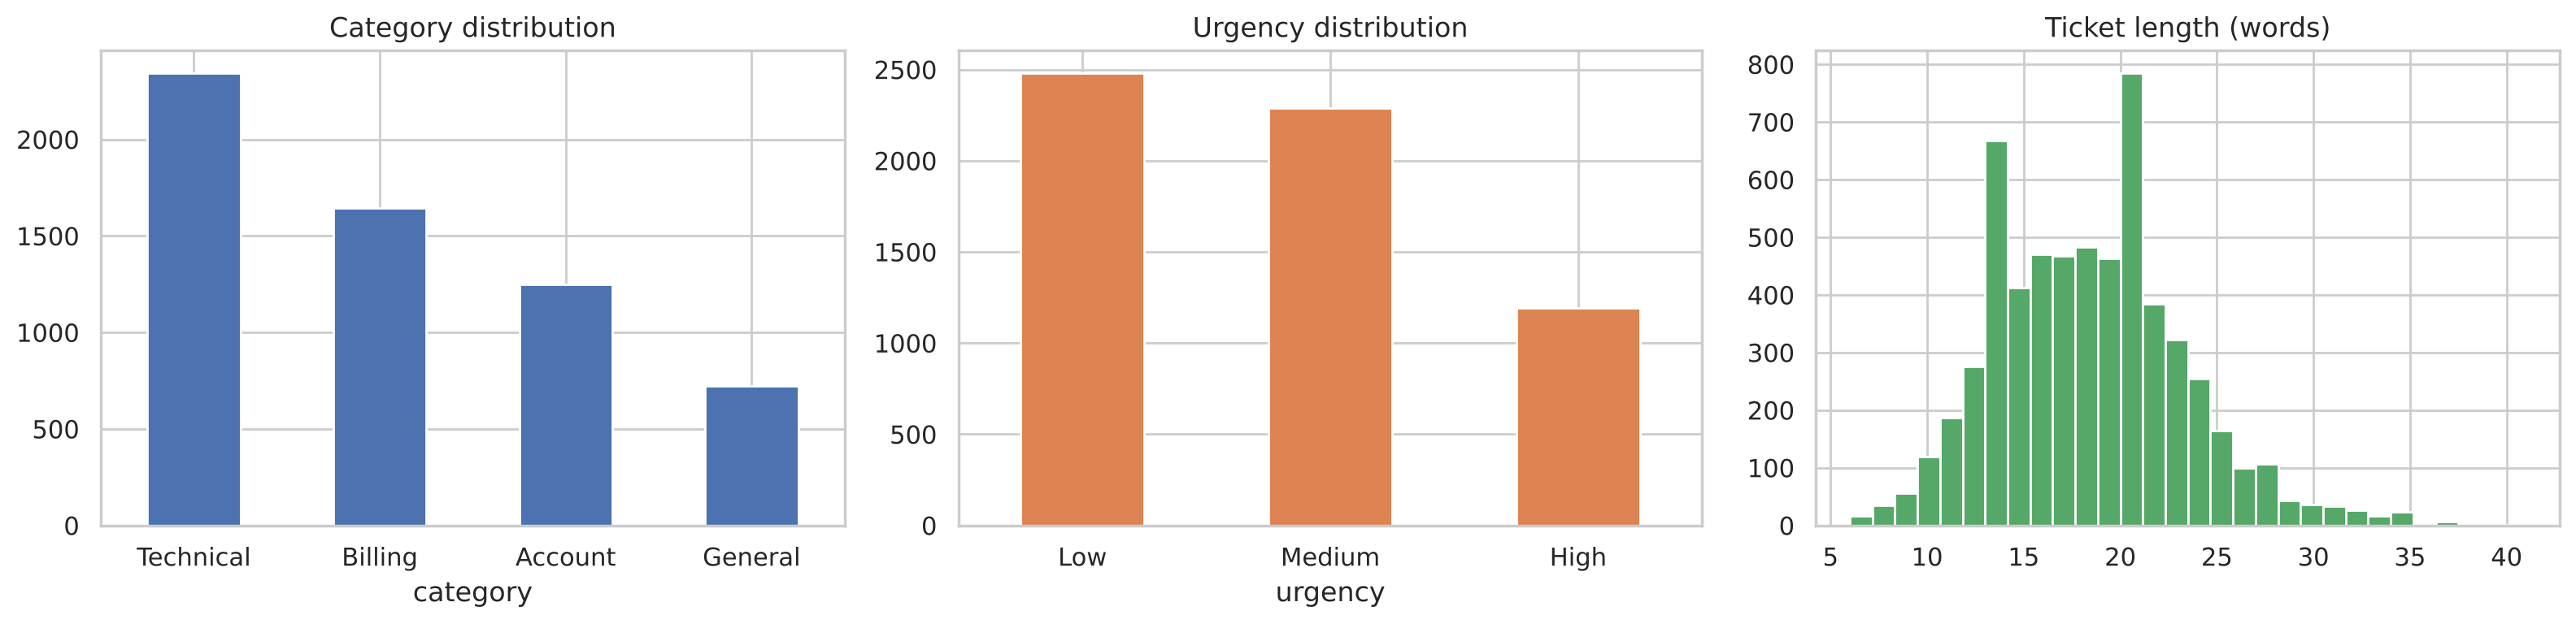

{'count': 5960.0, 'mean': 18.3, 'std': 4.9, 'min': 6.0, '25%': 15.0, '50%': 18.0, '75%': 22.0, 'max': 41.0}


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.category.value_counts().plot.bar(ax=ax[0], color="#4c72b0", title="Category distribution"); ax[0].tick_params(axis="x", rotation=0)
df.urgency.value_counts()[URGS].plot.bar(ax=ax[1], color="#dd8452", title="Urgency distribution"); ax[1].tick_params(axis="x", rotation=0)
df["n_words"] = df.clean.str.split().str.len()
ax[2].hist(df.n_words, bins=30, color="#55a868"); ax[2].set_title("Ticket length (words)")
plt.tight_layout(); plt.show()
print(df.n_words.describe().round(1).to_dict())

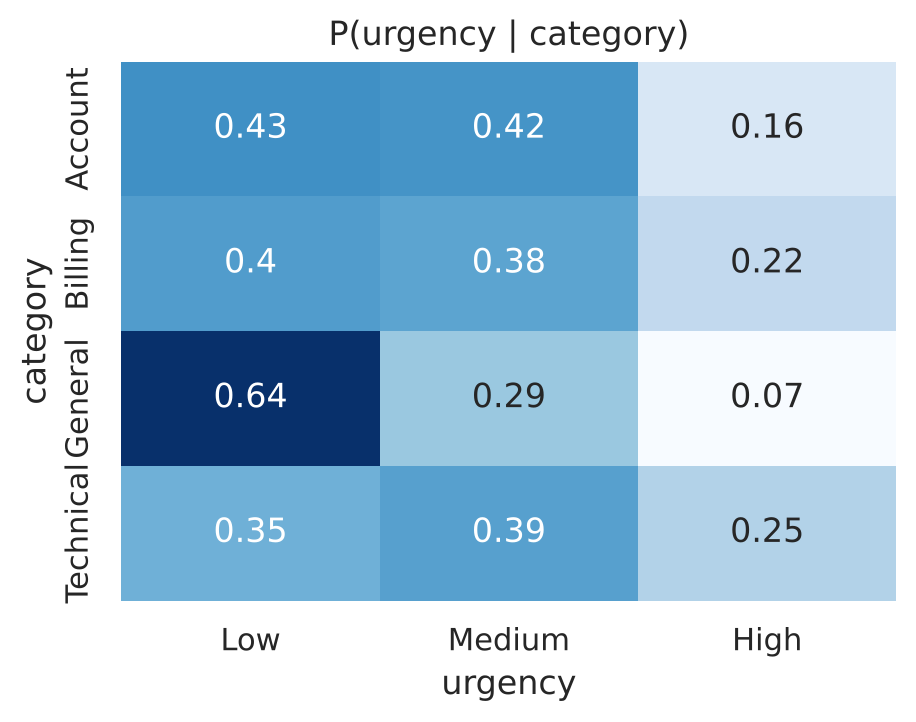

In [5]:
ct = pd.crosstab(df.category, df.urgency, normalize="index")[URGS].round(2)
plt.figure(figsize=(5, 3.5)); sns.heatmap(ct, annot=True, cmap="Blues", cbar=False); plt.title("P(urgency | category)"); plt.show()

In [6]:
def top_tokens(sub, k=8):
    c = Counter(t for s in sub.clean for t in set(tokenize(s)))
    return c
base = top_tokens(df); n = len(df)
rows = {}
for u in URGS:
    sub = df[df.urgency == u]; c = top_tokens(sub)
    # tokens most over-represented in this urgency level vs overall (lift), min support 30
    lift = {t: (c[t] / len(sub)) / (base[t] / n) for t in c if base[t] >= 30}
    rows[u] = [t for t, _ in sorted(lift.items(), key=lambda x: -x[1])[:8]]
pd.DataFrame(rows)

,Low,Medium,High
0,what,possible,critical
1,no,sorted,asap
2,rush,codes,every
3,get,choose,losing
4,chance,accepted,save
5,feature,getting,wait
6,export,appreciate,data
7,documentation,plan,platform


## 4. Class imbalance
Strategy: (1) **stratified** splits on the joint (category, urgency) label, (2) **class-weighted loss** (inverse frequency),
(3) judge by **macro-F1**, not accuracy, because accuracy can look fine while a rare class is ignored.


In [7]:
train, val, test = split(df)
def lr(cw): return Pipeline([("t", TfidfVectorizer(ngram_range=(1,2), min_df=2, sublinear_tf=True, token_pattern=r"<[a-z]+>|[a-z']+|[!?]")),
                             ("c", LogisticRegression(C=5, max_iter=2000, class_weight=cw))])
rare = df.category.value_counts().idxmin(); print("rarest class:", rare)
out = {}
for name, cw in [("no weighting", None), ("balanced", "balanced")]:
    p = lr(cw).fit(train.clean, train.category); pred = p.predict(val.clean)
    rep = classification_report(val.category, pred, output_dict=True, zero_division=0)
    out[name] = {"rare-class recall": rep[rare]["recall"], "rare-class F1": rep[rare]["f1-score"], "macro-F1": rep["macro avg"]["f1-score"]}
pd.DataFrame(out).T.round(3)

rarest class: General


,rare-class recall,rare-class F1,macro-F1
no weighting,0.888,0.913,0.948
balanced,0.897,0.877,0.937


**Reading the result.** Compare the two rows: if weighting raises rare-class recall but lowers its F1 or the overall macro-F1, it is trading
precision for recall and may not be worth it. On the synthetic data it did *not* help (imbalance is mild, rarest class ~12%).
It stays enabled as insurance for more skewed data, but re-check it on yours rather than assuming it helps.

## 5. Train / validation / test split

In [8]:
print({k: len(v) for k, v in {"train": train, "val": val, "test": test}.items()})
pd.DataFrame({n: d.category.value_counts(normalize=True) for n, d in [("train", train), ("val", val), ("test", test)]}).round(3)

{'train': 4172, 'val': 894, 'test': 894}


,train,val,test
category,,,
Technical,0.393,0.394,0.394
Billing,0.276,0.276,0.275
Account,0.210,0.210,0.208
General,0.121,0.120,0.123


## 6. Models
The two models were trained by `python -m triage.train` (same split, seeded). Here we load them and evaluate on the held-out **test** set.
Model selection was made on **validation** only; test is for reporting.

In [9]:
pred_base, pred_lstm = Predictor(ARTIFACTS, "baseline"), Predictor(ARTIFACTS, "bilstm")
Xte = list(test.text)                                     # raw text: the Predictor does its own cleaning, like the API
yc, yu = test.category.map(CATS.index).to_numpy(), test.urgency.map(URGS.index).to_numpy()
def probs(p):
    r = p.predict(Xte)
    f = lambda head, labels: np.array([[x[head]["probabilities"][l] for l in labels] for x in r])
    return f("category", CATS), f("urgency", URGS), r
P = {"baseline": probs(pred_base), "bilstm": probs(pred_lstm)}
for name, (pc, pu, _) in P.items():
    print(f"=== {name} | CATEGORY"); print(classification_report(yc, pc.argmax(1), target_names=CATS, digits=3))
    print(f"=== {name} | URGENCY");  print(classification_report(yu, pu.argmax(1), target_names=URGS, digits=3))

=== baseline | CATEGORY
              precision    recall  f1-score   support

     Billing      0.928     0.943     0.935       246
   Technical      0.966     0.960     0.963       352
     Account      0.939     0.914     0.926       186
     General      0.876     0.900     0.888       110

    accuracy                          0.938       894
   macro avg      0.927     0.929     0.928       894
weighted avg      0.939     0.938     0.939       894

=== baseline | URGENCY
              precision    recall  f1-score   support

         Low      0.912     0.922     0.917       372
      Medium      0.884     0.863     0.873       343
        High      0.913     0.933     0.923       179

    accuracy                          0.902       894
   macro avg      0.903     0.906     0.904       894
weighted avg      0.901     0.902     0.901       894

=== bilstm | CATEGORY
              precision    recall  f1-score   support

     Billing      0.968     0.980     0.974       246
   Tec

### Training curve (BiLSTM)

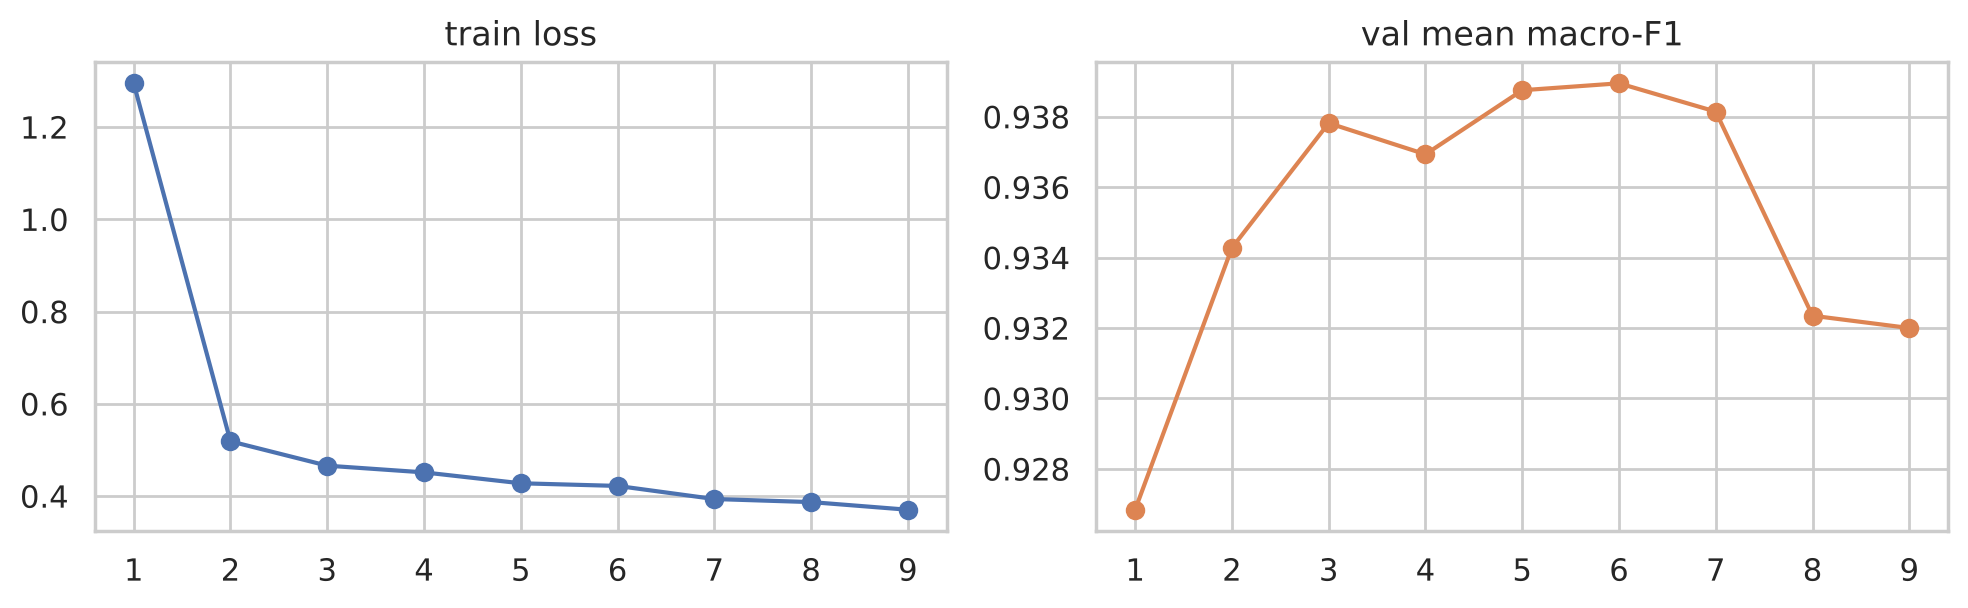

In [10]:
h = pd.DataFrame(meta["bilstm_history"]); fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h.epoch, h.train_loss, marker="o"); ax[0].set_title("train loss"); ax[1].plot(h.epoch, h.val_mean_macro_f1, marker="o", color="C1"); ax[1].set_title("val mean macro-F1")
plt.tight_layout(); plt.show()

### Confusion matrices (test set)

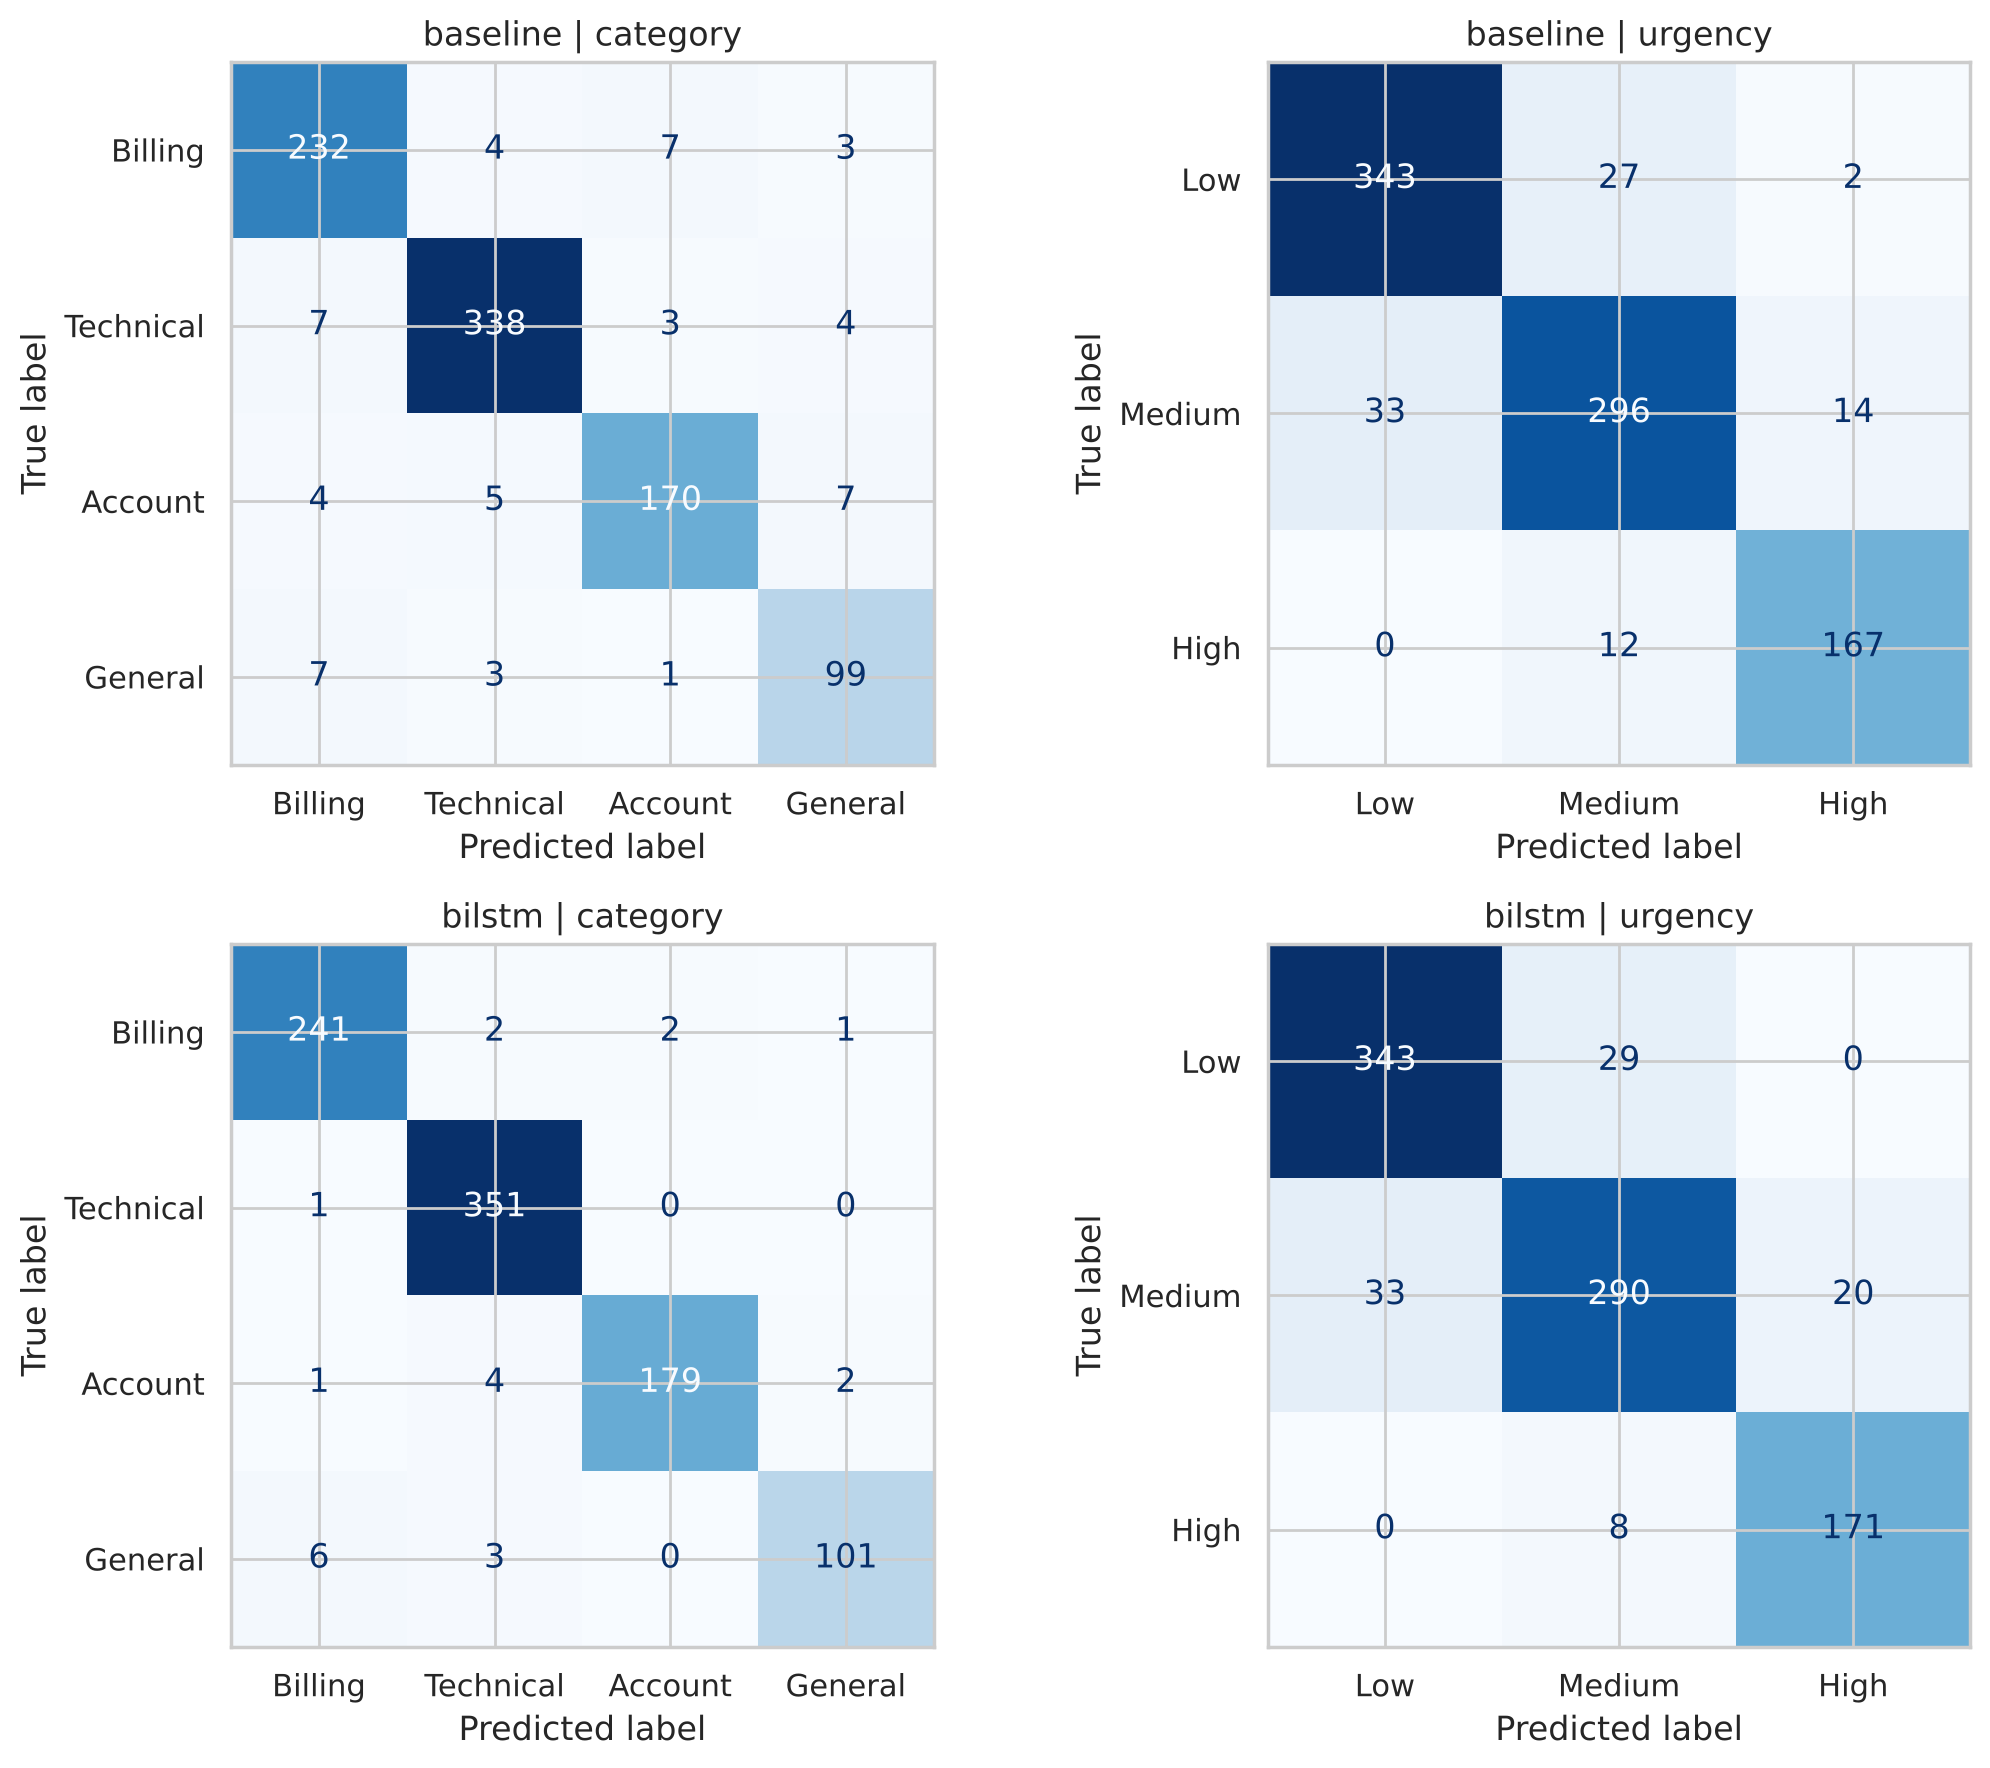

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, name in enumerate(["baseline", "bilstm"]):
    pc, pu, _ = P[name]
    for c, (y, p, labels, t) in enumerate([(yc, pc, CATS, "category"), (yu, pu, URGS, "urgency")]):
        ConfusionMatrixDisplay(confusion_matrix(y, p.argmax(1), labels=range(len(labels))), display_labels=labels).plot(ax=axes[r, c], cmap="Blues", colorbar=False)
        axes[r, c].set_title(f"{name} | {t}")
plt.tight_layout(); plt.show()

## 7. Baseline vs BiLSTM

In [12]:
rows = []
for name in ["baseline", "bilstm"]:
    r = meta["results"][name]
    rows.append({"model": name, "cat macro-F1": r["test"]["category"]["macro_f1"], "urg macro-F1": r["test"]["urgency"]["macro_f1"],
                 "mean macro-F1 (val)": r["val"]["mean_macro_f1"], "mean macro-F1 (test)": r["test"]["mean_macro_f1"],
                 "p50 latency ms": r["latency"]["p50_ms"], "p95 latency ms": r["latency"]["p95_ms"]})
cmp = pd.DataFrame(rows).set_index("model").round(4); display(cmp)
print(f"Selected model: {meta['selected_model']}  (val gain over baseline {meta['val_gain']:+.4f}, required margin {meta['selection_margin']})")

,cat macro-F1,urg macro-F1,mean macro-F1 (val),mean macro-F1 (test),p50 latency ms,p95 latency ms
model,,,,,,
baseline,0.9282,0.9043,0.9166,0.9162,0.7491,0.8099
bilstm,0.9698,0.9024,0.9388,0.9361,0.6592,1.3436


Selected model: bilstm  (val gain over baseline +0.0222, required margin 0.01)


## 8. Error analysis

In [13]:
pc, pu, res = P[meta["selected_model"]]
err = test.assign(pred_cat=[CATS[i] for i in pc.argmax(1)], pred_urg=[URGS[i] for i in pu.argmax(1)],
                  conf_cat=pc.max(1).round(2), conf_urg=pu.max(1).round(2))
wrong = err[(err.category != err.pred_cat) | (err.urgency != err.pred_urg)]
print(f"{len(wrong)} of {len(err)} test tickets have at least one wrong label")
wrong[["text", "category", "pred_cat", "conf_cat", "urgency", "pred_urg", "conf_urg"]].head(10)

108 of 894 test tickets have at least one wrong label


,text,category,pred_cat,conf_cat,urgency,pred_urg,conf_urg
1,"Hi, The font in the mobile app looks small on my tablet. I would appreciate a quick reply... Jon",Technical,Technical,0.96,Medium,Low,0.58
7,"Good morning, The app crashes whenever I open the reports page. My order number is 63097! Thanks",Technical,Technical,0.95,Low,Medium,0.81
11,"Hi, I am a journalist and we publish our article in two horus. My order number is 68099! Regards",General,General,0.99,Medium,High,0.97
19,"Hi team, The dark mode toggle looks slightly misaligned. My order number is 91144. I need this sorted this...",Technical,Technical,0.97,Medium,Low,0.59
21,"Hello, How do I change my display name. My order number is 63442... Thank you Ines",Account,Account,0.99,Medium,Low,0.97
22,"Hi team, I was charged for a plan I did not choose. My order number is 58425. No rush. Regards Carla",Billing,Billing,1.00,Low,Medium,0.93
51,"good morning, this is getting frustrating. a fraudulent charge from your company appeared on my car.d my o...",Billing,Billing,0.98,Medium,High,0.69
61,"Hello, I was charged for a plan I did not choose. My order number is 5968. Whenever you get a chance.",Billing,Billing,0.99,Low,Medium,0.92
68,"Hello, I need a formal quote for our company by Friday. Regards",General,General,1.00,Low,Medium,0.92
81,"Hi tea,m I was charged twice and my account is now overdrawn. My order number is 56165... Regards",Billing,Billing,0.99,Medium,High,0.98


In [14]:
# Where do category errors concentrate? (label noise is injected, so some "errors" are the label's fault)
cat_wrong = err[err.category != err.pred_cat]; print("category errors:", len(cat_wrong))
print(pd.crosstab(cat_wrong.category, cat_wrong.pred_cat))

category errors: 22
pred_cat   Account  Billing  General  Technical
category                                       
Account          0        1        2          4
Billing          2        0        1          2
General          0        6        0          3
Technical        0        1        0          0


### Is the confidence usable? Review-threshold trade-off

In [15]:
conf = np.minimum(pc.max(1), pu.max(1)); both_ok = ((pc.argmax(1) == yc) & (pu.argmax(1) == yu))
rows = []
for t in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = conf >= t
    rows.append({"threshold": t, "auto-handled %": keep.mean() * 100, "accuracy on auto-handled %": both_ok[keep].mean() * 100, "sent to human %": (~keep).mean() * 100})
pd.DataFrame(rows).round(1).set_index("threshold")

,auto-handled %,accuracy on auto-handled %,sent to human %
threshold,,,
0.0,100.0,87.9,0.0
0.5,99.8,88.0,0.2
0.6,94.0,90.4,6.0
0.7,89.9,91.4,10.1
0.8,85.8,92.7,14.2
0.9,72.7,94.5,27.3


## 9. Robustness: edge cases through the live Predictor

In [16]:
cases = ["The whole platform is down for our team, URGENT!",
         "my acount was hakced and someone is loging in right now",       # typos
         "My refund has not arrived and the app also crashes",             # two categories
         "what is the best pizza in town",                                 # off-topic
         "ok", "asdkjh qwe zzzz",
         "I was charged twice. No rush though, whenever you get a chance."]  # mixed urgency signals
rows = []
for t, r in zip(cases, pred_lstm.predict(cases)):
    rows.append({"text": t, "category": f'{r["category"]["label"]} ({r["category"]["confidence"]:.2f})', "urgency": f'{r["urgency"]["label"]} ({r["urgency"]["confidence"]:.2f})',
                 "review": r["needs_human_review"], "why": ",".join(r["review_reasons"])})
pd.DataFrame(rows)

,text,category,urgency,review,why
0,"The whole platform is down for our team, URGENT!",Technical (0.93),High (1.00),False,
1,my acount was hakced and someone is loging in right now,Account (0.99),High (1.00),False,
2,My refund has not arrived and the app also crashes,Billing (0.95),Medium (0.59),True,low_confidence
3,what is the best pizza in town,Technical (0.65),Low (0.63),True,unfamiliar_text
4,ok,Technical (0.46),High (0.43),True,"low_confidence,unfamiliar_text"
5,asdkjh qwe zzzz,Technical (0.67),High (0.53),True,"low_confidence,unfamiliar_text"
6,"I was charged twice. No rush though, whenever you get a chance.",Billing (0.98),Low (0.95),False,
